# King County House Prices Project

Your task is to **predict the sale price of a house** in King County with a regression model, and to **tune** the model with cross-validation. In the project you combine the methods you already know into one complete analysis.

The task below follows the steps of a machine learning project, in a single pass:

![The project in one pass, from top to bottom: 1. goal and metric, 2. get the data, 3. a train-test split into training data and locked test data. Steps 4 and 5 (explore, baselines) use only the training data. Steps 6 and 7 form the model selection loop: feature engineering, set hyperparameters, train model(s) and calculate the cross-validation score, then repeat. In step 8, the test data is unlocked and the models are scored on the test set](assets/king_county_project_workflow.png)

# Data Description

King County covers Seattle and its surroundings. The data ships with this repository as **two tables**:

- `data/king_county_house_sales.csv`: one row per sale, with the date and the price
- `data/king_county_house_details.csv`: one row per house, with its physical attributes

`01_loading_the_data.ipynb` guides you through combining them into one table.

| Column | Table | Description |
| :-- | :-- | :-- |
| `date` | sales | date the house was sold |
| `price` | sales | sale price in dollars, the prediction target |
| `house_id` | sales | identifier of the house, matches `id` in the details table |
| `id` | sales | identifier of the sale |
| `id` | details | unique identifier for a house |
| `bedrooms` | details | number of bedrooms |
| `bathrooms` | details | number of bathrooms |
| `sqft_living` | details | square footage of the home |
| `sqft_lot` | details | square footage of the lot |
| `floors` | details | total floors (levels) in the house |
| `waterfront` | details | whether the house has a view to a waterfront |
| `view` | details | quality of the view |
| `condition` | details | overall condition of the house |
| `grade` | details | overall grade given to the housing unit, based on the King County grading system |
| `sqft_above` | details | square footage of the house apart from the basement |
| `sqft_basement` | details | square footage of the basement |
| `yr_built` | details | year the house was built |
| `yr_renovated` | details | year the house was renovated |
| `zipcode` | details | zip code |
| `lat` | details | latitude coordinate |
| `long` | details | longitude coordinate |
| `sqft_living15` | details | square footage of the interior living space of the nearest 15 neighbours |
| `sqft_lot15` | details | square footage of the land lots of the nearest 15 neighbours |

## Task

1. **Set your goal.** Decide which metric you use to judge the model, and explain why.
2. **Get the data.** Complete `01_loading_the_data.ipynb` first: it combines the two tables and saves the result as `data/eda.csv`, which you load here.
3. **Split the data into a training and a test set.** Use `train_test_split` once. Choose the size of the test set with `test_size`, and fix the `random_state`, so that you get the same split every time you run the notebook. Keep the features and the target together: the result should be two DataFrames, `df_train` and `df_test`, that both still contain the `price` column. You do not need a separate validation set: in step 7, cross-validation on the training set takes its place. Do not look at `df_test` until step 8.
4. **Explore the training set.** Which columns are related to the price, and which one most strongly? Which columns are skewed, which values are missing, and which features contain the same information?

> [!IMPORTANT]
> **Keep a record of every change you make to the training data by hand.** In step 8 you apply exactly the same changes to the test set. This covers, for example, a new column such as the age of the house at sale, or dropping the identifiers `id` and `house_id` and the `date` column. Transformations inside your `Pipeline` (imputing, scaling, encoding) are applied to the test set automatically, with the values learned on the training data.

5. **Separate the features from the target, and build two baselines.** Split `df_train` into `X_train` and `y_train`; the test set stays untouched until step 8. Then build two simple models that your models have to beat:
    - a **mean baseline** with [`DummyRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html), which predicts the mean price of the training set for every house, and
    - a **rule-based baseline** built from the column most strongly related to the price in step 4. Learn the values of the rule on the training data.
6. **Build a preprocessing pipeline and train a linear model.** Put every transformation into a `Pipeline` with a `ColumnTransformer`, so that it is fitted on the training data only, and train a regularised linear model, for example `Ridge`, with as many features as possible.
7. **Tune and compare models with cross-validation.** Train and tune at least two models, for example `Ridge` on the original features and on polynomial features: first a wide `RandomizedSearchCV`, then a narrow `GridSearchCV` around what it found. Choose the best model by its cross-validated score. **Save every model in its own variable** (and the values of your rule), so that you can evaluate all of them in the last step.
8. **Prepare the test set and evaluate all models at the very end.** First apply to `df_test` the changes you made by hand to the training data, and split it into `X_test` and `y_test`. Then calculate the **training and the test scores of every model** with your chosen metric, including both baselines, and collect them in **one table**: one row per model, with columns for the training and the test scores. Compare the models: which ones beat the baselines, and how large is the difference between training and test scores? Finally, **analyse the residuals** of your best model: for which houses is it wrong, and how large are the errors?

In [1]:
# Import the libraries you need for this project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

In [6]:
# 2. Get the data
RSEED = 42

df = pd.read_csv("data/eda.csv")

In [7]:
# 3. Split the data into a training and a test set
df_train, df_test = train_test_split(df, test_size=0.2, random_state=RSEED)

print(f"train: {df_train.shape[0]} rows")
print(f"test:  {df_test.shape[0]} rows")

train: 17277 rows
test:  4320 rows


In [8]:
# 4. Explore the training set
df_train.info()

<class 'pandas.DataFrame'>
Index: 17277 entries, 6243 to 15795
Data columns (total 23 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           17277 non-null  str    
 1   price          17277 non-null  float64
 2   house_id       17277 non-null  int64  
 3   id             17277 non-null  int64  
 4   id_details     17277 non-null  int64  
 5   bedrooms       17277 non-null  float64
 6   bathrooms      17277 non-null  float64
 7   sqft_living    17277 non-null  float64
 8   sqft_lot       17277 non-null  float64
 9   floors         17277 non-null  float64
 10  waterfront     15370 non-null  float64
 11  view           17224 non-null  float64
 12  condition      17277 non-null  int64  
 13  grade          17277 non-null  int64  
 14  sqft_above     17277 non-null  float64
 15  sqft_basement  16921 non-null  float64
 16  yr_built       17277 non-null  int64  
 17  yr_renovated   14208 non-null  float64
 18  zipcode        1727

In [9]:
# missing values per column
df_train.isna().sum().sort_values(ascending=False).head(8)

yr_renovated     3069
waterfront       1907
sqft_basement     356
view               53
date                0
price               0
house_id            0
bathrooms           0
dtype: int64

yr_renovated: most houses were never renovated (0), so missing values are filled with 0.
waterfront: about 11% missing, almost all known values are 0, so missing values are filled with the most common value.
sqft_basement: can be calculated as sqft_living - sqft_above.
view: only 53 missing, filled with the most common value (0).

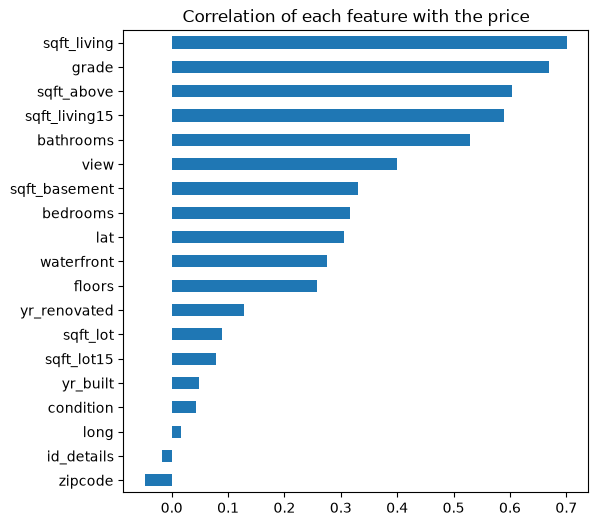

In [10]:
# correlation of every numeric column with the price
corr_price = (
    df_train.drop(columns=["id", "house_id"])
    .corr(numeric_only=True)["price"]
    .drop("price")
    .sort_values()
)
corr_price.plot.barh(figsize=(6, 6))
plt.title("Correlation of each feature with the price");

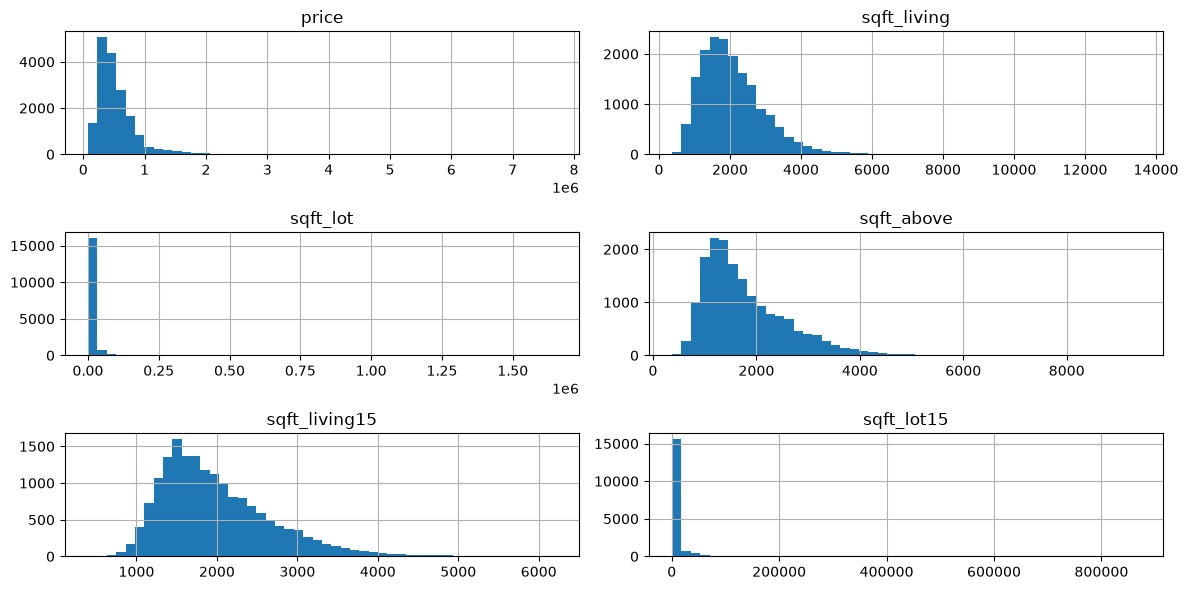

In [11]:
# which columns are skewed?
df_train[["price", "sqft_living", "sqft_lot", "sqft_above", "sqft_living15", "sqft_lot15"]].hist(
    bins=50, figsize=(12, 6)
)
plt.tight_layout();

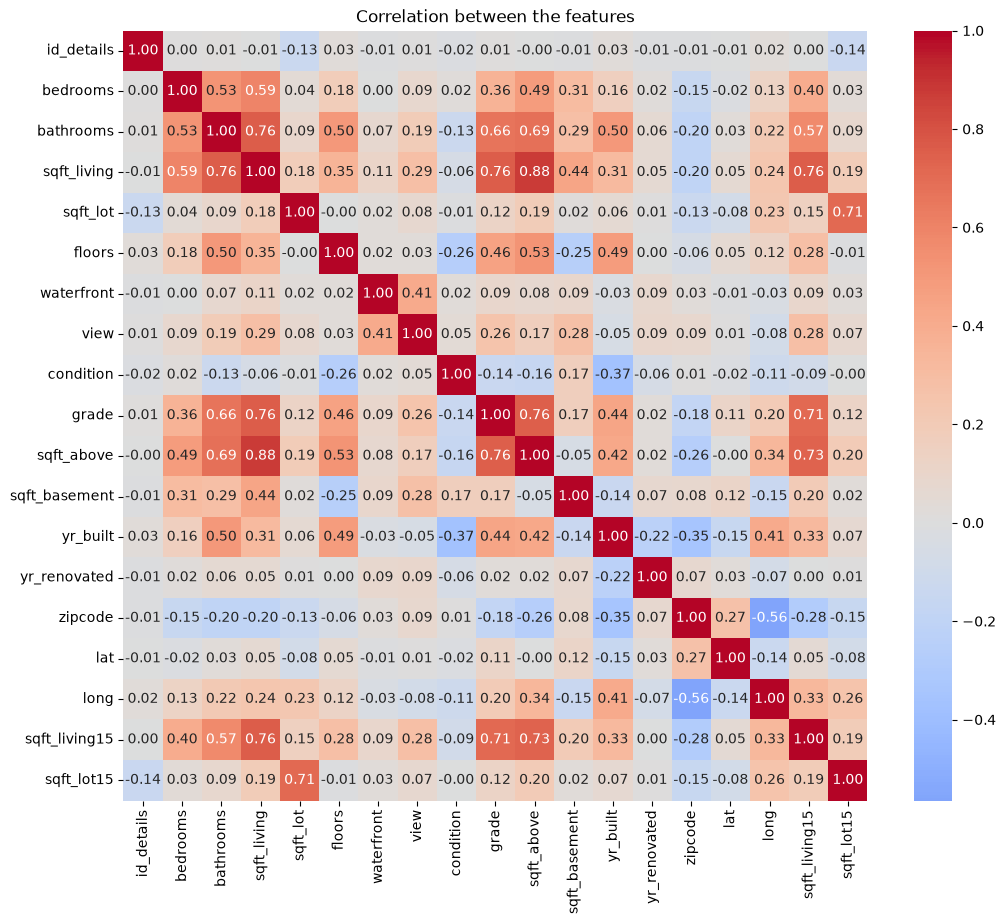

In [12]:
# correlation of the features with each other
plt.figure(figsize=(12, 10))
sns.heatmap(
    df_train.drop(columns=["id", "house_id", "price"]).corr(numeric_only=True),
    annot=True, fmt=".2f", cmap="coolwarm", center=0,
)
plt.title("Correlation between the features");

In [21]:
# all manual changes in one function, so that step 8 can apply exactly the same to the test set
def prepare(data):
    data = data.copy()

    # fill missing basement area from the other two areas
    data["sqft_basement"] = data["sqft_living"] - data["sqft_above"]

    # new column: age of the house at the time of sale
    sale_year = pd.to_datetime(data["date"]).dt.year
    data["age_at_sale"] = sale_year - data["yr_built"]

    # drop identifiers, the date, and sqft_above (almost the same as sqft_living)
    data = data.drop(columns=["id", "house_id", "id_details", "date", "yr_built", "sqft_above"])
    return data


df_train_prep = prepare(df_train)
df_train_prep.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_basement,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,age_at_sale
6243,332500.0,4.0,2.00,1440.0,4855.0,2.0,0.0,0.0,4,7,0.0,0.0,98144,47.5717,-122.287,1300.0,4080.0,42
8986,390000.0,3.0,1.75,1430.0,9857.0,1.0,0.0,2.0,4,7,290.0,0.0,98045,47.4964,-121.771,1310.0,9880.0,35
9419,800000.0,4.0,2.75,3120.0,5000.0,2.0,0.0,0.0,3,9,0.0,0.0,98074,47.5940,-122.062,3200.0,5000.0,4
10155,462000.0,4.0,2.50,2060.0,6958.0,1.0,0.0,0.0,3,7,840.0,NaN,98034,47.7251,-122.168,1760.0,7350.0,41
10436,695000.0,3.0,2.00,2500.0,4080.0,1.5,0.0,0.0,5,7,820.0,0.0,98103,47.6813,-122.346,1550.0,3060.0,92


In [22]:
# 5. Separate the features from the target
X_train = df_train_prep.drop(columns="price")
y_train = df_train_prep["price"]

print(X_train.shape, y_train.shape)

(17277, 17) (17277,)


In [24]:
# mean baseline: predicts the mean price of the training set for every house
cv = KFold(5, shuffle=True, random_state=RSEED)

mean_baseline = DummyRegressor(strategy="mean")
mean_rmse = -cross_val_score(
    mean_baseline, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error"
).mean()

print(f"Mean baseline RMSE: {mean_rmse:,.0f} $")

Mean baseline RMSE: 368,207 $


In [25]:
# rule-based baseline: price = typical price per sqft * living area
# learn the value of the rule on the training data only
price_per_sqft = (y_train / X_train["sqft_living"]).median()
print(f"Typical price per sqft: {price_per_sqft:,.0f} $")

rule_pred_train = price_per_sqft * X_train["sqft_living"]
rule_rmse_train = root_mean_squared_error(y_train, rule_pred_train)
print(f"Rule baseline RMSE (train): {rule_rmse_train:,.0f} $")

Typical price per sqft: 244 $
Rule baseline RMSE (train): 267,068 $


In [26]:
from sklearn.preprocessing import FunctionTransformer

# 6. Preprocessing pipeline
log_cols = ["sqft_living", "sqft_lot", "sqft_living15", "sqft_lot15"]
most_frequent_cols = ["waterfront", "view"]
zero_cols = ["yr_renovated"]
cat_cols = ["zipcode"]
num_cols = ["bedrooms", "bathrooms", "floors", "condition", "grade",
            "sqft_basement", "lat", "long", "age_at_sale"]

preprocessor = ColumnTransformer([
    ("log", Pipeline([
        ("log", FunctionTransformer(np.log1p)),
        ("scale", StandardScaler()),
    ]), log_cols),
    ("most_frequent", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("scale", StandardScaler()),
    ]), most_frequent_cols),
    ("zero", Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value=0)),
        ("scale", StandardScaler()),
    ]), zero_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
])

In [27]:
# number of different zip codes in the training data
X_train["zipcode"].nunique()

70

In [28]:
# full pipeline: preprocessing + regularised linear model
ridge_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", Ridge()),
])

ridge_scores = -cross_val_score(
    ridge_pipe, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error"
)
print(f"Ridge RMSE (CV): {ridge_scores.mean():,.0f} $  (fold std {ridge_scores.std():,.0f} $)")

Ridge RMSE (CV): 176,671 $  (fold std 16,661 $)


In [29]:
# 7. Tune Ridge on the original features: wide random search first
ridge_random = RandomizedSearchCV(
    ridge_pipe,
    {"model__alpha": loguniform(1e-3, 1e3)},
    n_iter=20, cv=cv, scoring="neg_root_mean_squared_error",
    random_state=RSEED, n_jobs=-1,
)
ridge_random.fit(X_train, y_train)

print("Best alpha:", round(ridge_random.best_params_["model__alpha"], 4))
print(f"Ridge RMSE (CV): {-ridge_random.best_score_:,.0f} $")

Best alpha: 1.4078
Ridge RMSE (CV): 176,666 $


In [30]:
# narrow grid around the alpha the random search found
ridge_grid = GridSearchCV(
    ridge_pipe,
    {"model__alpha": [0.5, 0.75, 1, 1.4, 2, 3, 5]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
ridge_grid.fit(X_train, y_train)

print("Best alpha:", ridge_grid.best_params_["model__alpha"])
print(f"Ridge RMSE (CV): {-ridge_grid.best_score_:,.0f} $")

# save the best Ridge model in its own variable
ridge_best = ridge_grid.best_estimator_

Best alpha: 1.4
Ridge RMSE (CV): 176,666 $


In [32]:
# Model 2: Ridge on polynomial features (only on the numeric columns, not on the zip codes)
numeric_prep = ColumnTransformer([
    ("log", FunctionTransformer(np.log1p), log_cols),
    ("most_frequent", SimpleImputer(strategy="most_frequent"), most_frequent_cols),
    ("zero", SimpleImputer(strategy="constant", fill_value=0), zero_cols),
    ("num", "passthrough", num_cols),
])

numeric_poly = Pipeline([
    ("prep", numeric_prep),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scale", StandardScaler()),
])

poly_preprocessor = ColumnTransformer([
    ("numeric", numeric_poly, log_cols + most_frequent_cols + zero_cols + num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

poly_pipe = Pipeline([
    ("prep", poly_preprocessor),
    ("model", Ridge()),
])

# wide random search
poly_random = RandomizedSearchCV(
    poly_pipe,
    {"model__alpha": loguniform(1e-3, 1e3)},
    n_iter=20, cv=cv, scoring="neg_root_mean_squared_error",
    random_state=RSEED, n_jobs=-1,
)
poly_random.fit(X_train, y_train)

print("Best alpha:", round(poly_random.best_params_["model__alpha"], 4))
print(f"Poly Ridge RMSE (CV): {-poly_random.best_score_:,.0f} $")

Best alpha: 0.0013
Poly Ridge RMSE (CV): 137,076 $


In [33]:
# narrow grid: also below 0.001, because the best value was at the edge of the search range
poly_grid = GridSearchCV(
    poly_pipe,
    {"model__alpha": [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
poly_grid.fit(X_train, y_train)

print("Best alpha:", poly_grid.best_params_["model__alpha"])
print(f"Poly Ridge RMSE (CV): {-poly_grid.best_score_:,.0f} $")

# save the best polynomial model in its own variable
poly_best = poly_grid.best_estimator_

Best alpha: 0.0003
Poly Ridge RMSE (CV): 136,977 $


In [34]:
# compare both tuned models: mean CV error and fold-to-fold variation
for name, search in [("Ridge", ridge_grid), ("Poly Ridge", poly_grid)]:
    i = search.best_index_
    mean = -search.cv_results_["mean_test_score"][i]
    std = search.cv_results_["std_test_score"][i]
    print(f"{name:12} RMSE {mean:,.0f} $  (fold std {std:,.0f} $)")

Ridge        RMSE 176,666 $  (fold std 16,698 $)
Poly Ridge   RMSE 136,977 $  (fold std 9,713 $)


In [35]:
# 8. Apply exactly the same manual changes to the test set
df_test_prep = prepare(df_test)

X_test = df_test_prep.drop(columns="price")
y_test = df_test_prep["price"]

print(X_test.shape, y_test.shape)
print("same columns as train:", list(X_test.columns) == list(X_train.columns))

(4320, 17) (4320,)
same columns as train: True


In [36]:
# mean baseline, fitted on the training data
mean_model = DummyRegressor(strategy="mean").fit(X_train, y_train)

# predictions of every model on train and test
predictions = {
    "Mean baseline": (mean_model.predict(X_train), mean_model.predict(X_test)),
    "Rule baseline (244 $/sqft)": (
        price_per_sqft * X_train["sqft_living"],
        price_per_sqft * X_test["sqft_living"],
    ),
    "Ridge": (ridge_best.predict(X_train), ridge_best.predict(X_test)),
    "Poly Ridge": (poly_best.predict(X_train), poly_best.predict(X_test)),
}

rows = []
for name, (pred_train, pred_test) in predictions.items():
    rows.append({
        "model": name,
        "train RMSE": root_mean_squared_error(y_train, pred_train),
        "test RMSE": root_mean_squared_error(y_test, pred_test),
        "train MAE": mean_absolute_error(y_train, pred_train),
        "test MAE": mean_absolute_error(y_test, pred_test),
    })

results = pd.DataFrame(rows).set_index("model").round(0)
results

,train RMSE,test RMSE,train MAE,test MAE
model,,,,
Mean baseline,368958.0,360907.0,235058.0,231542.0
Rule baseline (244 $/sqft),267068.0,260103.0,168642.0,165076.0
Ridge,175500.0,179124.0,102715.0,104462.0
Poly Ridge,130505.0,134512.0,78718.0,79990.0


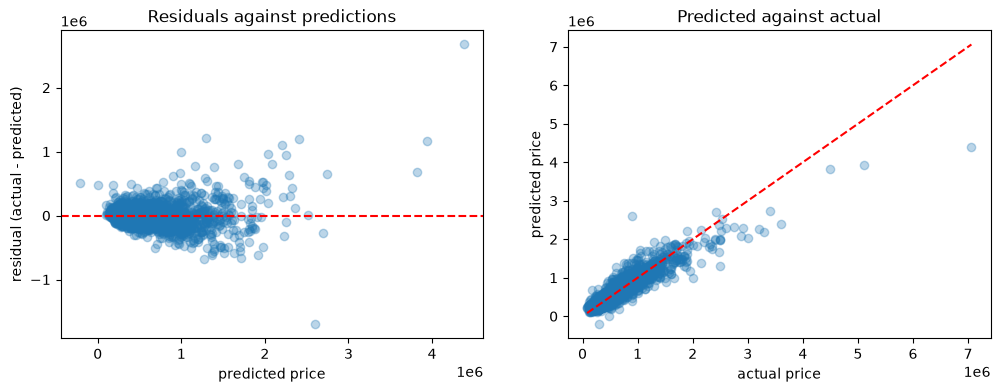

In [37]:
# residuals of the best model on the test set
y_pred = poly_best.predict(X_test)
residuals = y_test - y_pred

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.scatter(y_pred, residuals, alpha=0.3)
ax1.axhline(0, color="red", linestyle="--")
ax1.set_xlabel("predicted price")
ax1.set_ylabel("residual (actual - predicted)")
ax1.set_title("Residuals against predictions")

ax2.scatter(y_test, y_pred, alpha=0.3)
lims = [y_test.min(), y_test.max()]
ax2.plot(lims, lims, color="red", linestyle="--")
ax2.set_xlabel("actual price")
ax2.set_ylabel("predicted price")
ax2.set_title("Predicted against actual");

In [38]:
# mean error per price group: test houses split into 4 equal groups by their real price
price_group = pd.qcut(y_test, 4, labels=["cheapest 25%", "2nd", "3rd", "most expensive 25%"])
residuals.groupby(price_group).agg(["mean", "count"]).round(0)

,mean,count
price,,
cheapest 25%,-15517.0,1080
2nd,-7067.0,1090
3rd,-5342.0,1070
most expensive 25%,28820.0,1080


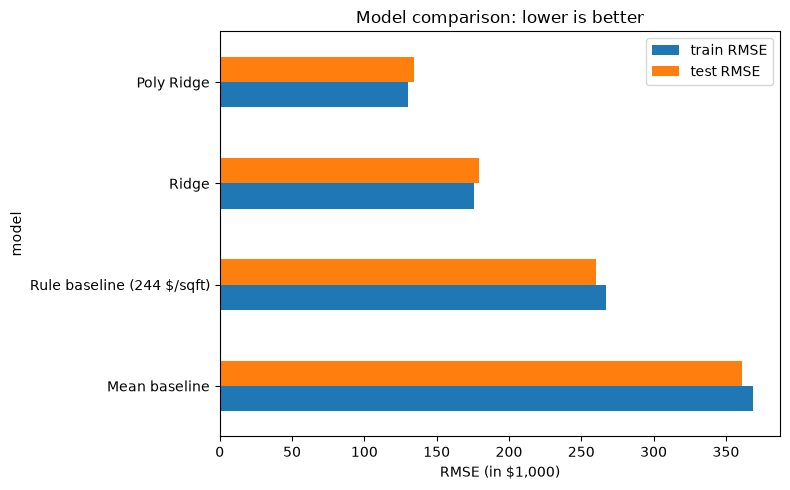

In [39]:
# bar chart of train and test RMSE for every model, in 1,000 $
(results[["train RMSE", "test RMSE"]] / 1000).plot.barh(figsize=(8, 5))
plt.title("Model comparison: lower is better")
plt.xlabel("RMSE (in $1,000)")
plt.ylabel("model")
plt.tight_layout();